# Лабораторная работа 1

1) Классификация данных методом k ближайших соседей ( kNN)

2) Классификация данных методом опорных векторов (SVM)

3) Построение softmax-классификатора

Вариант 1: задания 1 и 2 на наборе данных CIFAR-10

Вариант 2: задания 1 и 2 на наборе данных MNIST

Вариант 3: задания 1 и 3 на наборе данных CIFAR-10

Вариант 4: задания 1 и 3 на наборе данных MNIST

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере. 

## 1. Классификация данных методом k ближайших соседей ( kNN)

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from digits_data import load_variant2
np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['image.cmap'] = 'gray'

from scripts.classifiers import KNearestNeighbor, LinearSVM
from sklearn.model_selection import StratifiedKFold
from scripts.classifiers.linear_svm import svm_loss_naive, svm_loss_vectorized
from scripts.gradient_check import eval_numerical_gradient
from time import perf_counter


**Вариант 2.** Используется `sklearn.datasets.load_digits` (1797 цифр 8×8),
указанный в методических материалах под названием MNIST. Это отдельный набор,
не полный MNIST 28×28. Во всех работах одно стратифицированное разбиение
60/20/20 с `random_state=42`. Гиперпараметры выбираются без тестовой выборки.
Интенсивности делятся на 16; среднее для центрирования считается только по train.


1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST 
sklearn.datasets import load_digits
digits = load_digits()

In [2]:
raw = load_variant2(center=False)
print('Набор: sklearn digits, 1797 изображений 8×8, 10 классов')


Набор: sklearn digits, 1797 изображений 8×8, 10 классов


In [3]:
X_train, y_train = raw['X_train'], raw['y_train']
X_test, y_test = raw['X_test'], raw['y_test']
print('train:', X_train.shape, 'test:', X_test.shape)


train: (1077, 64) test: (360, 64)


1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



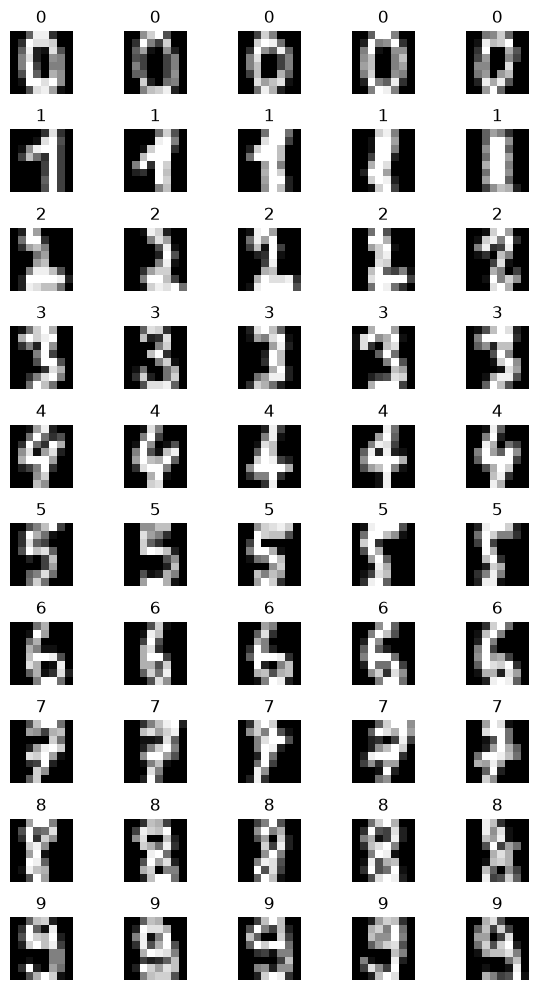

In [4]:
fig, axes = plt.subplots(10, 5, figsize=(6, 10))
for label in range(10):
    for j, image in enumerate(X_train[y_train == label][:5]):
        axes[label, j].imshow(image.reshape(8, 8))
        axes[label, j].axis('off')
        axes[label, j].set_title(str(label))
plt.tight_layout(); plt.show()


1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив. 

In [5]:
print('После развёртки:', X_train.shape, X_test.shape)
assert X_train.shape[1] == 64


После развёртки: (1077, 64) (360, 64)


1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке. 

In [6]:
from scripts.classifiers import KNearestNeighbor

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

1.5 Выполните классификацию на тестовой выборке

In [7]:
dists = classifier.compute_distances_no_loops(X_test)
y_pred = classifier.predict_labels(dists, k=1)
# Все три реализации должны вычислять одинаковые расстояния.
for fn in (classifier.compute_distances_one_loop, classifier.compute_distances_two_loops):
    np.testing.assert_allclose(fn(X_test[:8]), dists[:8], atol=1e-7)
print('Первые предсказания:', y_pred[:20])


Первые предсказания: [5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]


1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки. 


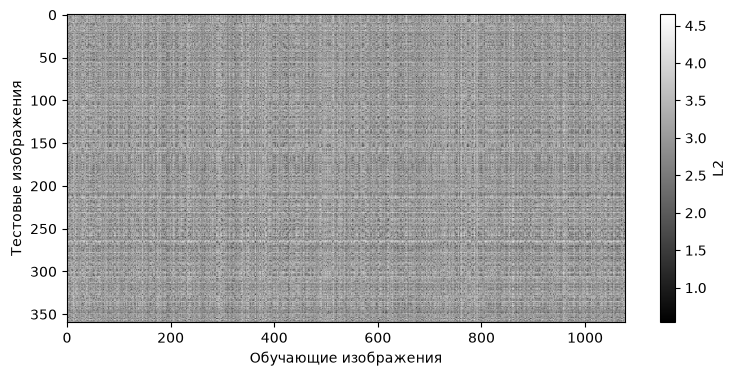

In [8]:
plt.imshow(dists, aspect='auto'); plt.colorbar(label='L2'); plt.xlabel('Обучающие изображения'); plt.ylabel('Тестовые изображения'); plt.show()



1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [9]:
knn_initial_acc = np.mean(y_pred == y_test)
print(f'k=1, test accuracy: {knn_initial_acc:.4f}')


k=1, test accuracy: 0.9861


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

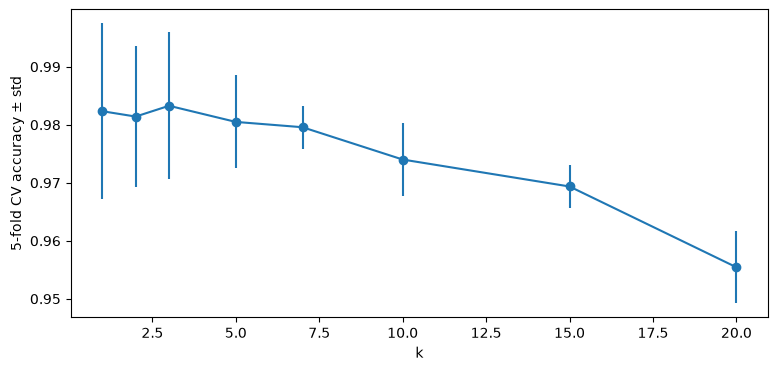

In [10]:
# Зависимость строится по внутренним фолдам train; test не используется для выбора k.
k_choices = [1, 2, 3, 5, 7, 10, 15, 20]
k_to_accuracies = {k: [] for k in k_choices}
for tr, va in StratifiedKFold(5, shuffle=True, random_state=42).split(X_train, y_train):
    fold = KNearestNeighbor(); fold.train(X_train[tr], y_train[tr])
    distances = fold.compute_distances_no_loops(X_train[va])
    for k in k_choices:
        k_to_accuracies[k].append(np.mean(fold.predict_labels(distances, k) == y_train[va]))
plt.errorbar(k_choices, [np.mean(k_to_accuracies[k]) for k in k_choices],
             yerr=[np.std(k_to_accuracies[k]) for k in k_choices], marker='o')
plt.xlabel('k'); plt.ylabel('5-fold CV accuracy ± std'); plt.show()


1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


In [11]:
best_k = max(k_choices, key=lambda k: (np.mean(k_to_accuracies[k]), -k))
for k in k_choices: print(k, np.mean(k_to_accuracies[k]), np.std(k_to_accuracies[k]))
print('Лучшее k:', best_k)


1 0.9823385012919896 0.015122979244454025
2 0.9814168819982774 0.012140334337496351
3 0.9832773471145565 0.012694601854006197
5 0.9804952627045649 0.008003275485841484
7 0.9795779500430664 0.003688866179147309
10 0.97400947459087 0.006257908572154537
15 0.9693626184323858 0.0036805558311371837
20 0.955439276485788 0.006248233233550833
Лучшее k: 3



1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [12]:
classifier.train(X_train, y_train)
knn_test_acc = np.mean(classifier.predict(X_test, k=best_k) == y_test)
print(f'Итог kNN: k={best_k}, test accuracy={knn_test_acc:.4f}')


Итог kNN: k=3, test accuracy=0.9861


1.11 Сделайте выводы по результатам 1 части задания.

**Вывод.** kNN не оптимизирует веса: обучение — запоминание выборки.
Векторизация даёт те же L2-расстояния, что циклы. Малое k учитывает локальную структуру,
большое сглаживает границы и может смешивать похожие цифры. k выбран по пяти фолдам train;
точные значения и итоговая доля верных ответов приведены выше.


## 2.  Классификация данных методом опорных векторов (SVM)

2.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [13]:
data = load_variant2()
X_train, y_train = data['X_train'].copy(), data['y_train']
X_val, y_val = data['X_val'].copy(), data['y_val']
X_test, y_test = data['X_test'].copy(), data['y_test']
for split in ['train', 'val', 'test']: print(split, data['X_' + split].shape)


train (1077, 64)
val (360, 64)
test (360, 64)


2.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

2.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву дынных и заполните ее 1.

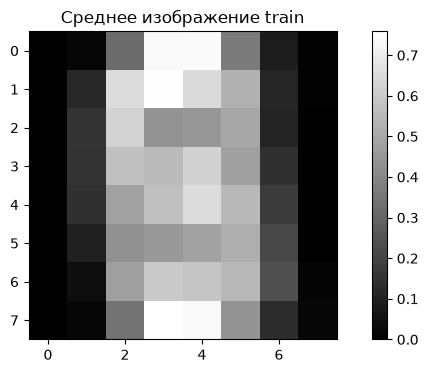

(1077, 65) (360, 65) (360, 65)


In [14]:
mean_image = data['mean_image']
plt.imshow(mean_image); plt.title('Среднее изображение train'); plt.colorbar(); plt.show()
# Центрирование уже выполнено загрузчиком с одним средним train.
X_train, X_val, X_test = [np.column_stack([x, np.ones(len(x))]) for x in (X_train, X_val, X_test)]
X_dev, y_dev = X_train[:80], y_train[:80]
print(X_train.shape, X_val.shape, X_test.shape)


2.4 Реализуйте loss-функции в scripts/classifiers/linear_svm.py



In [15]:
W = np.random.randn(X_train.shape[1], 10) * 1e-4
loss, grad = svm_loss_naive(W, X_dev, y_dev, 5e-6)
print('Initial hinge loss:', loss)


Initial hinge loss: 8.999770211792898



2.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [16]:
for reg in [0., 0.05]:
    loss, grad = svm_loss_naive(W, X_dev, y_dev, reg)
    numeric = eval_numerical_gradient(lambda w: svm_loss_naive(w, X_dev, y_dev, reg)[0], W, verbose=False)
    error = np.max(np.abs(numeric - grad))
    print('reg:', reg, 'max absolute gradient error:', error)
    np.testing.assert_allclose(numeric, grad, atol=1e-7, rtol=1e-5)


reg: 0.0 max absolute gradient error: 7.533118018265839e-10


reg: 0.05 max absolute gradient error: 8.034705678561238e-10


2.6 Сравните svm_loss_naive и svm_loss_vectorized реализации

In [17]:
results = []
for fn in (svm_loss_naive, svm_loss_vectorized):
    start = perf_counter(); loss, grad = fn(W, X_dev, y_dev, 5e-6)
    results.append((loss, grad)); print(fn.__name__, 'seconds:', perf_counter() - start)
np.testing.assert_allclose(results[0][0], results[1][0])
np.testing.assert_allclose(results[0][1], results[1][1], atol=1e-12)
print('Реализации совпадают')


svm_loss_naive seconds: 0.001574188000063259
svm_loss_vectorized seconds: 9.516799991615699e-05
Реализации совпадают


2.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

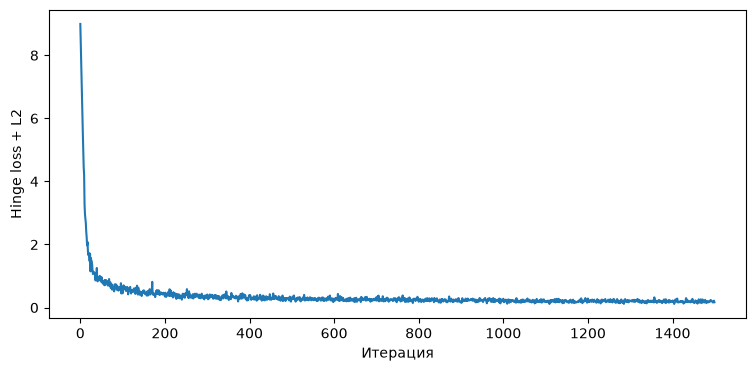

In [18]:
np.random.seed(42)
svm = LinearSVM()
loss_hist = svm.train(X_train, y_train, learning_rate=0.03, reg=1e-3, num_iters=1500)
plt.plot(loss_hist); plt.xlabel('Итерация'); plt.ylabel('Hinge loss + L2'); plt.show()


In [19]:
y_train_pred = svm.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.979573
validation accuracy: 0.955556


2.8 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [20]:
learning_rates = [0.01, 0.03, 0.1]
regularization_strengths = [1e-4, 1e-3, 1e-2]
results = {}; best_val = -1; best_svm = None
# Hold-out кросс-валидация: обучение на train, сравнение по val.
for lr in learning_rates:
    for reg in regularization_strengths:
        np.random.seed(42)
        candidate = LinearSVM()
        candidate.train(X_train, y_train, learning_rate=lr, reg=reg, num_iters=2000)
        train_acc = np.mean(candidate.predict(X_train) == y_train)
        val_acc = np.mean(candidate.predict(X_val) == y_val)
        results[lr, reg] = (train_acc, val_acc)
        print(f'lr={lr:g}, reg={reg:g}: train={train_acc:.4f}, val={val_acc:.4f}')
        if val_acc > best_val:
            best_val, best_svm, best_params = val_acc, candidate, (lr, reg)
svm_test_acc = np.mean(best_svm.predict(X_test) == y_test)
print('Лучшие lr, reg:', best_params, 'val:', best_val, 'test:', svm_test_acc)


lr=0.01, reg=0.0001: train=0.9694, val=0.9611


lr=0.01, reg=0.001: train=0.9684, val=0.9611


lr=0.01, reg=0.01: train=0.9675, val=0.9556


lr=0.03, reg=0.0001: train=0.9851, val=0.9639


lr=0.03, reg=0.001: train=0.9842, val=0.9583


lr=0.03, reg=0.01: train=0.9731, val=0.9722


lr=0.1, reg=0.0001: train=0.9935, val=0.9694


lr=0.1, reg=0.001: train=0.9926, val=0.9778


lr=0.1, reg=0.01: train=0.9768, val=0.9694
Лучшие lr, reg: (0.1, 0.001) val: 0.9777777777777777 test: 0.95


**Вывод.** Линейный SVM минимизирует многоклассовую hinge loss с L2-штрафом.
Циклическая и векторная реализации совпали; градиент проверен конечными разностями
с регуляризацией и без. Скорость обучения и регуляризация выбраны по val.
Сравнение итогового SVM с kNN ниже; SVM строит линейные границы, kNN — локальные.


Раздел 3 (softmax-классификатор) относится к вариантам 3 и 4 и для варианта 2 не требуется. Softmax используется в нейронных сетях следующих работ.


In [21]:
print(f'kNN test: {knn_test_acc:.2%}; SVM test: {svm_test_acc:.2%}')


kNN test: 98.61%; SVM test: 95.00%


**Результат запуска.** Выбрано k=3 (CV 98,33%, test 98,61%). Лучший SVM: lr=0.1, reg=0.001, val 97,78%, test 95,00%. На этом разбиении локальный kNN лучше разделяет цифры, чем линейный SVM.
